# Chapitre 3 - Cours 1 : Pourquoi l'évaluation est difficile, et les métriques de modélisation du langage

Le chapitre 3 du livre ouvre le premier des deux chapitres consacrés à l'**évaluation**,
que l'auteure présente comme le principal obstacle à la mise en production d'une
application d'IA. Ce premier notebook couvre les sections *Challenges of Evaluating
Foundation Models* et *Understanding Language Modeling Metrics* (entropie, entropie
croisée, bits par caractère et par octet, perplexité, interprétation et usages).

**Plan.**

1. Pourquoi évaluer un modèle de fondation est difficile : réponses ouvertes, saturation
   des benchmarks, carte des méthodes du chapitre.
2. L'entropie, quantité moyenne d'information d'un token (l'exemple du carré).
3. L'entropie croisée et la divergence KL, avec la démonstration de
   $H(P, Q) = H(P) + D_{KL}(P \| Q)$.
4. Bits par caractère (BPC), bits par octet (BPB) et perplexité : toutes les conversions
   démontrées, et le lien avec la compression.
5. Le calcul effectif sur GPT-2 et Qwen2.5, token par token.
6. Interpréter une perplexité : structure, contexte, vocabulaire, post-entraînement.
7. Textes naturels, mélangés et mémorisés : la perplexité comme détecteur de contamination.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16   # laisse la place aux sous-titres
llm.seed_everything(0)
pd.set_option("display.precision", 3)
QWEN_BASE = "Qwen/Qwen2.5-0.5B"   # modèle de base (pré-entraîné seulement)
MODELES = {"GPT-2 (124 M)": llm.BASE, "Qwen2.5-0.5B base": QWEN_BASE, "Qwen2.5-0.5B Instruct": llm.SMALL}

## 1. Pourquoi évaluer un modèle de fondation est difficile (section *Challenges of Evaluating Foundation Models*)

Évaluer un classifieur est simple : sa sortie appartient à un petit ensemble de classes et
l'on compare à l'étiquette attendue. Le livre (section *Challenges of Evaluating
Foundation Models*) liste cinq raisons pour lesquelles c'est beaucoup plus dur avec un
modèle de fondation :

| Difficulté | Conséquence pratique |
|---|---|
| Plus le modèle est **intelligent**, plus il est dur de juger (une démonstration de niveau doctorat, un résumé cohérent d'un livre qu'on n'a pas lu) | évaluer demande vérification des faits, raisonnement, expertise |
| Les tâches sont **ouvertes** : une même entrée admet d'innombrables bonnes réponses | impossible de dresser la liste exhaustive des réponses correctes |
| Les modèles sont des **boîtes noires** (architecture, données, entraînement non publiés) | on ne peut juger que les sorties |
| Les **benchmarks saturent** vite | il faut sans cesse en créer de nouveaux |
| Le **périmètre** s'élargit : on évalue aussi des capacités inconnues | l'évaluation devient exploration |

**Illustration du caractère ouvert.** Demandons au même petit modèle de traduire
« Comment ça va ? » vingt fois en échantillonnant (température 1). Combien de réponses
distinctes, toutes acceptables ou presque ?

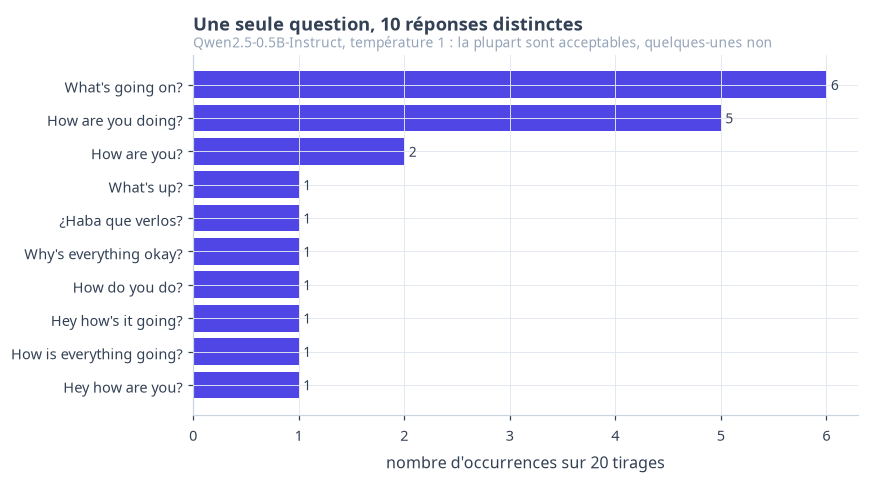

In [2]:
sorties = [llm.chat("Translate into English, answer with the translation only: « Comment ça va ? »",
                    temperature=1.0, seed=s, max_new_tokens=15) for s in range(20)]
comptes = pd.Series([s.strip().strip('"').strip("«» ") for s in sorties]).value_counts()
fig, ax = plt.subplots(figsize=(8, 0.35 * len(comptes) + 1))
ax.barh(comptes.index[::-1], comptes.values[::-1], color=INDIGO)
ax.set_xlabel("nombre d'occurrences sur 20 tirages")
ax.set_title(f"Une seule question, {len(comptes)} réponses distinctes")
subtitle(ax, "Qwen2.5-0.5B-Instruct, température 1 : la plupart sont acceptables, quelques-unes non")
annotate_bars(ax, "{:.0f}")
plt.tight_layout(); plt.show()

Même pour une phrase de trois mots, la liste des réponses valides n'est pas fermée (le
petit modèle produit aussi quelques sorties fausses ou hors sujet, qu'il faudra savoir
détecter) : une
évaluation par comparaison à « la » bonne réponse marquerait faux des sorties
parfaitement correctes. Pour un résumé ou un programme, l'espace explose.

**La saturation des benchmarks.** Un benchmark est saturé lorsqu'un modèle y atteint le
score maximal (ou le plafond humain) : il ne discrimine plus. Le livre cite plusieurs
remplacements successifs ; la figure les replace sur une frise.

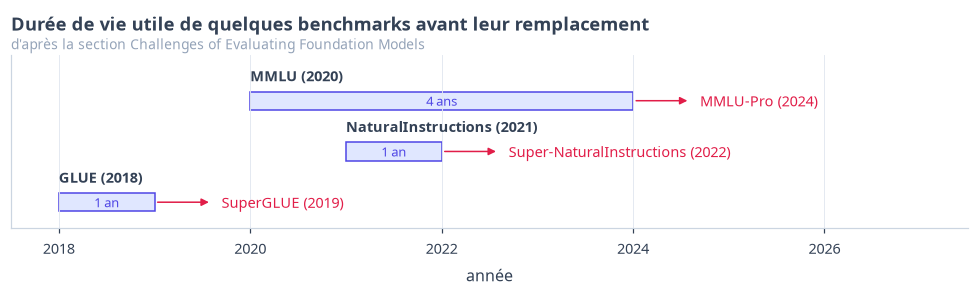

In [3]:
bench = [("GLUE", 2018, 2019, "SuperGLUE"), ("NaturalInstructions", 2021, 2022, "Super-NaturalInstructions"),
         ("MMLU", 2020, 2024, "MMLU-Pro")]
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, (nom, debut, fin, succ) in enumerate(bench):
    ax.barh(i, fin - debut, left=debut, color=LIGHT[INDIGO], edgecolor=INDIGO, height=0.36)
    ax.text(debut, i + 0.3, f"{nom} ({debut})", va="bottom", fontsize=9.5, fontweight="bold", color=SLATE)
    ax.text(debut + (fin - debut) / 2, i, f"{fin - debut} an" + ("s" if fin - debut > 1 else ""),
            ha="center", va="center", fontsize=8.5, color=INDIGO)
    ax.annotate("", xy=(fin + 0.6, i), xytext=(fin, i), arrowprops=dict(arrowstyle="-|>", color=ROSE))
    ax.text(fin + 0.7, i, f"{succ} ({fin})", va="center", fontsize=9.5, color=ROSE)
ax.set_yticks([]); ax.set_ylim(-0.5, len(bench) - 0.1); ax.set_xlim(2017.5, 2027.5); ax.set_xlabel("année")
ax.set_title("Durée de vie utile de quelques benchmarks avant leur remplacement")
subtitle(ax, "d'après la section Challenges of Evaluating Foundation Models")
plt.tight_layout(); plt.show()

**Carte du chapitre.** Le livre classe les méthodes automatiques en deux familles :
l'évaluation **exacte** (le verdict ne dépend pas de qui évalue) et l'évaluation
**subjective** (le score dépend du juge). Les métriques de modélisation du langage
servent de *proxy* en amont. Le diagramme ci-dessous sert de fil conducteur aux quatre
notebooks de cours.

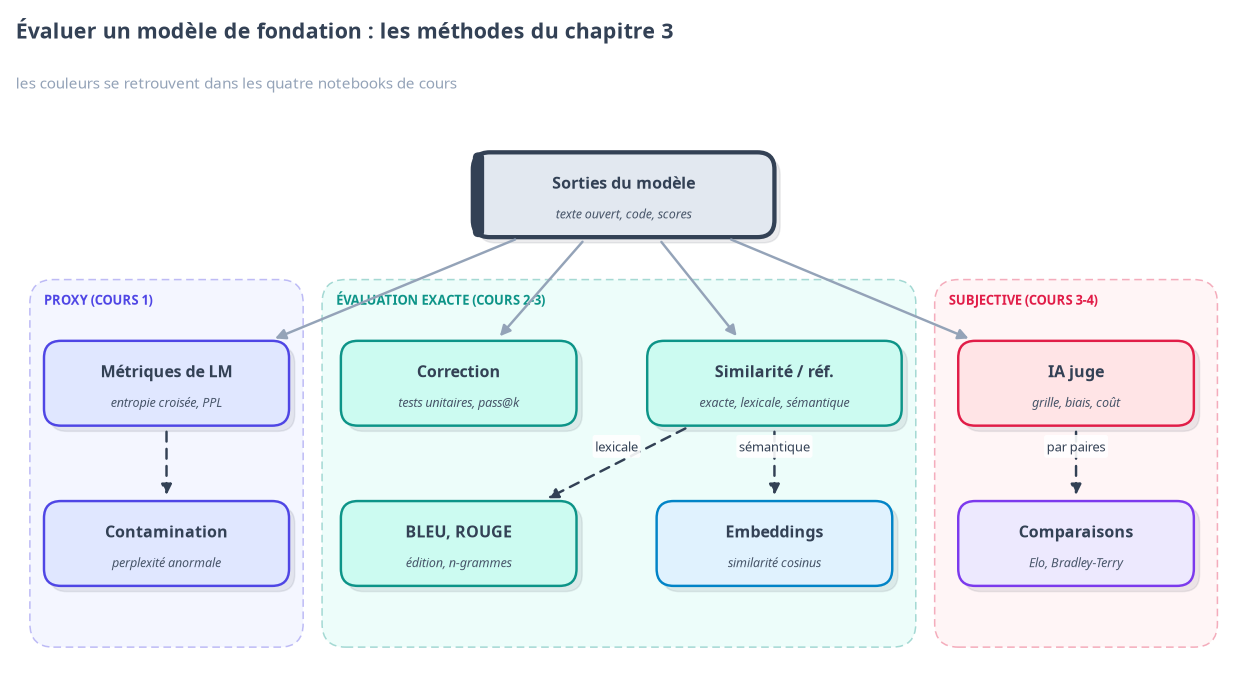

In [4]:
d = Diagram(13, 6.0, title="Évaluer un modèle de fondation : les méthodes du chapitre 3",
            subtitle="les couleurs se retrouvent dans les quatre notebooks de cours")
d.box("root", 6.5, 5.0, "Sorties du modèle", sub="texte ouvert, code, scores", color=SLATE, w=3.2, kind="model")
d.group(0.2, 0.2, 3.1, 4.1, "proxy (cours 1)", INDIGO)
d.group(3.3, 0.2, 9.6, 4.1, "évaluation exacte (cours 2-3)", TEAL)
d.group(9.8, 0.2, 12.8, 4.1, "subjective (cours 3-4)", ROSE)
d.box("lm", 1.65, 3.0, "Métriques de LM", sub="entropie croisée, PPL", color=INDIGO, w=2.6)
d.box("cont", 1.65, 1.3, "Contamination", sub="perplexité anormale", color=INDIGO, w=2.6)
d.box("fc", 4.75, 3.0, "Correction", sub="tests unitaires, pass@k", color=TEAL, w=2.5)
d.box("sim", 8.1, 3.0, "Similarité / réf.", sub="exacte, lexicale, sémantique", color=TEAL, w=2.7)
d.box("emb", 8.1, 1.3, "Embeddings", sub="similarité cosinus", color=SKY, w=2.5)
d.box("bleu", 4.75, 1.3, "BLEU, ROUGE", sub="édition, n-grammes", color=TEAL, w=2.5)
d.box("judge", 11.3, 3.0, "IA juge", sub="grille, biais, coût", color=ROSE, w=2.5)
d.box("cmp", 11.3, 1.3, "Comparaisons", sub="Elo, Bradley-Terry", color=VIOLET, w=2.5)
for n in ["lm", "fc", "sim", "judge"]:
    d.arrow("root", n, color=GRAY)
d.arrow("lm", "cont", style="dashed")
d.arrow("sim", "bleu", "lexicale", style="dashed")
d.arrow("sim", "emb", "sémantique", style="dashed")
d.arrow("judge", "cmp", "par paires", style="dashed")
d.show()

> **À retenir.** Les sorties ouvertes, l'intelligence croissante des modèles, leur
> opacité et la saturation rapide des benchmarks rendent l'évaluation des modèles de
> fondation plus difficile que celle du ML classique. Le chapitre propose une boîte à
> outils : métriques de modélisation du langage (proxy), évaluation exacte (tests,
> similarité) et évaluation subjective (juges IA, comparaisons).

## 2. Entropie : l'information moyenne d'un token (section *Entropy*)

**Motivation.** Avant de mesurer la qualité d'un modèle de langage, il faut savoir à quel
point le langage lui-même est prévisible. C'est ce que mesure l'**entropie**
(Shannon, 1948-1951).

**Définition.** Pour une variable $X$ de loi $P$ sur un vocabulaire $\mathcal V$ :
$$H(P) = -\sum_{x \in \mathcal V} P(x)\,\log_2 P(x) = \mathbb E_{x\sim P}\big[-\log_2 P(x)\big].$$
La quantité $-\log_2 P(x)$ est la **surprise** (ou information) du symbole $x$ : un
événement certain ne surprend pas (0 bit), un événement de probabilité $1/2$ apporte
1 bit, un événement de probabilité $1/1024$ apporte 10 bits. L'entropie est la surprise
moyenne.

**L'exemple du carré.** Le livre décrit deux « langues » pour désigner une position dans
un carré : (a) deux tokens *haut* / *bas*, (b) quatre tokens *haut-gauche*, *haut-droite*,
*bas-gauche*, *bas-droite*. Si les positions sont uniformes, la langue (a) a une
entropie de 1 bit, la langue (b) de 2 bits : chaque token de (b) est plus informatif,
mais plus difficile à prédire.

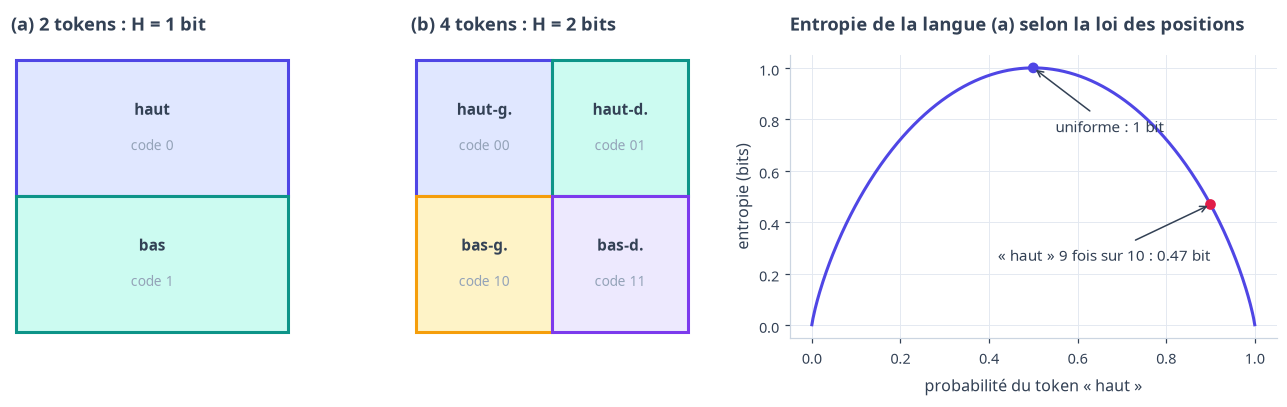

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
for ax, (titre, cases) in zip(axes[:2], [
        ("(a) 2 tokens : H = 1 bit", [((0, 0.5), 1, 0.5, "haut", "0"), ((0, 0), 1, 0.5, "bas", "1")]),
        ("(b) 4 tokens : H = 2 bits", [((0, 0.5), 0.5, 0.5, "haut-g.", "00"), ((0.5, 0.5), 0.5, 0.5, "haut-d.", "01"),
                                       ((0, 0), 0.5, 0.5, "bas-g.", "10"), ((0.5, 0), 0.5, 0.5, "bas-d.", "11")])]):
    for k, ((x, y), w, h, nom, code) in enumerate(cases):
        c = [INDIGO, TEAL, AMBER, VIOLET][k]
        ax.add_patch(Rectangle((x, y), w, h, facecolor=LIGHT[c], edgecolor=c, lw=2))
        ax.text(x + w / 2, y + h / 2 + 0.05, nom, ha="center", fontsize=10, fontweight="bold", color=SLATE)
        ax.text(x + w / 2, y + h / 2 - 0.08, f"code {code}", ha="center", fontsize=9, color=GRAY)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(titre)
p = np.linspace(1e-4, 1 - 1e-4, 400)
axes[2].plot(p, [ev.entropy([q, 1 - q]) for q in p], color=INDIGO)
axes[2].scatter([0.5, 0.9], [1, ev.entropy([0.9, 0.1])], color=[INDIGO, ROSE], zorder=3)
axes[2].annotate("uniforme : 1 bit", (0.5, 1), (0.55, 0.75), arrowprops=dict(arrowstyle="->", color=SLATE))
axes[2].annotate(f"« haut » 9 fois sur 10 : {ev.entropy([0.9, 0.1]):.2f} bit", (0.9, ev.entropy([0.9, 0.1])),
                 (0.42, 0.25), arrowprops=dict(arrowstyle="->", color=SLATE))
axes[2].set_xlabel("probabilité du token « haut »"); axes[2].set_ylabel("entropie (bits)")
axes[2].set_title("Entropie de la langue (a) selon la loi des positions")
finish(fig)
plt.show()

La courbe de droite montre la seconde intuition du livre : l'entropie mesure la
**difficulté de prédire** le prochain token. Si l'on sait que la position est « en
haut » 9 fois sur 10, un token n'apporte plus que 0,47 bit en moyenne. À la limite, si
l'on peut prédire parfaitement ce que l'autre va dire, ce qu'il dit ne contient aucune
information.

**Propriétés utiles** (démontrées dans l'exercice 3.1) :
$0 \le H(P) \le \log_2 |\mathcal V|$, avec égalité à droite si et seulement si $P$ est
uniforme. Pour un vocabulaire de 151 643 tokens (Qwen2.5), l'entropie maximale est
$\log_2 151\,643 \approx 17{,}2$ bits par token.

In [6]:
V = 151_643
langues = {"(a) 2 positions": [0.5, 0.5], "(b) 4 positions": [0.25] * 4, "(b) non uniforme": [0.7, 0.1, 0.1, 0.1],
           "dé à 6 faces": [1 / 6] * 6, "anglais par lettre (estimation de Shannon)": None}
tab = pd.DataFrame({"entropie (bits)": [ev.entropy(p) if p else 1.0 for p in langues.values()]}, index=langues.keys())
tab.loc["vocabulaire Qwen, uniforme"] = math.log2(V)
tab

,entropie (bits)
(a) 2 positions,1.000
(b) 4 positions,2.000
(b) non uniforme,1.357
dé à 6 faces,2.585
anglais par lettre (estimation de Shannon),1.000
"vocabulaire Qwen, uniforme",17.210


> **À retenir.** L'entropie $H(P) = -\sum P \log_2 P$ est le nombre moyen de bits
> nécessaires pour coder un token avec un code optimal. Elle est d'autant plus grande que
> la langue est imprévisible, et maximale ($\log_2|\mathcal V|$) pour une loi uniforme.

## 3. Entropie croisée et divergence KL (section *Cross Entropy*)

**Motivation.** On ne connaît jamais la vraie loi $P$ du langage : on dispose d'un
modèle $Q$ appris sur des données. L'**entropie croisée** mesure le coût moyen (en bits)
de coder des données de loi $P$ avec un code optimisé pour $Q$ :
$$H(P, Q) = -\sum_x P(x)\,\log_2 Q(x) = \mathbb E_{x\sim P}\big[-\log_2 Q(x)\big].$$
Sur un jeu de données $x_1, \dots, x_N$ tiré de $P$, on l'estime par la moyenne empirique
$-\frac1N \sum_i \log_2 Q(x_i \mid x_{<i})$ : c'est exactement la **fonction de perte**
d'entraînement d'un modèle de langage (log-vraisemblance négative moyenne).

**Décomposition** (le livre l'énonce, démontrons-la). En ajoutant et retranchant
$\log P(x)$ :
$$H(P, Q) = -\sum_x P(x)\log P(x) + \sum_x P(x)\log\frac{P(x)}{Q(x)} = H(P) + D_{KL}(P\,\|\,Q).$$

**La KL est positive (inégalité de Gibbs).** Par concavité du logarithme (inégalité de
Jensen), $-D_{KL}(P\|Q) = \sum_x P(x) \log \frac{Q(x)}{P(x)} \le \log \sum_x P(x)\frac{Q(x)}{P(x)} = \log \sum_x Q(x) \le \log 1 = 0.$
Donc $D_{KL} \ge 0$, avec égalité si et seulement si $Q = P$. Conséquence :
$H(P, Q) \ge H(P)$. **Aucun modèle ne peut descendre sous l'entropie des données** ; un
modèle parfait l'atteint exactement. L'entropie croisée d'un modèle est donc son
approximation (par excès) de l'entropie de ses données. $\blacksquare$

**Vérification numérique** sur des lois aléatoires, puis visualisation : pour une langue
à deux tokens de vraie loi $P = (0{,}7 ; 0{,}3)$, l'entropie croisée d'un modèle
$Q = (q ; 1-q)$ est minimale en $q = 0{,}7$ et vaut alors $H(P)$.

In [7]:
rng = np.random.default_rng(0)
lignes = []
for _ in range(5):
    P, Q = rng.dirichlet(np.ones(5)), rng.dirichlet(np.ones(5))
    lignes.append(dict(H_P=ev.entropy(P), KL_PQ=ev.kl_divergence(P, Q), H_PQ=ev.cross_entropy(P, Q),
                       H_QP=ev.cross_entropy(Q, P)))
df = pd.DataFrame(lignes)
df["H_P + KL"] = df.H_P + df.KL_PQ
df.round(4)

,H_P,KL_PQ,H_PQ,H_QP,H_P + KL
0,1.605,1.390,2.994,4.127,2.994
1,1.529,1.642,3.170,7.520,3.170
2,1.738,0.920,2.658,2.641,2.658
3,2.140,0.349,2.490,2.289,2.490
4,2.004,0.821,2.824,2.563,2.824


Les colonnes `H_PQ` et `H_P + KL` coïncident, et `H_PQ` diffère de `H_QP` : l'entropie
croisée **n'est pas symétrique**, comme le souligne le livre.

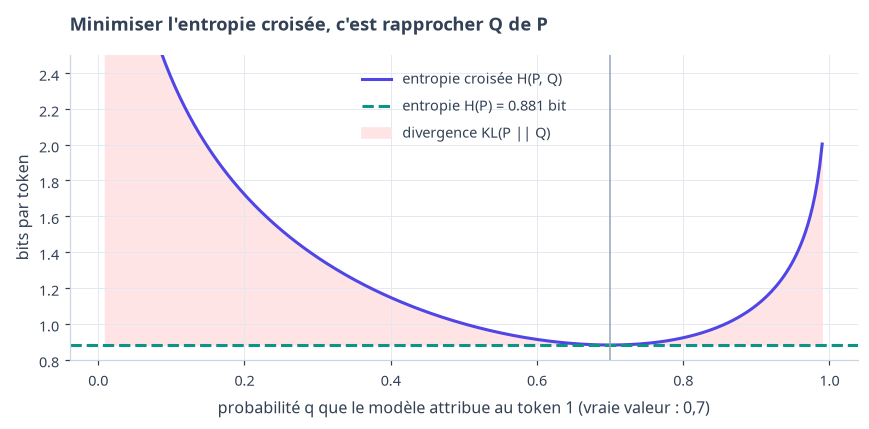

In [8]:
pv = 0.7
q = np.linspace(0.01, 0.99, 300)
ce = np.array([ev.cross_entropy([pv, 1 - pv], [x, 1 - x]) for x in q])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(q, ce, color=INDIGO, label="entropie croisée H(P, Q)")
ax.axhline(ev.entropy([pv, 1 - pv]), color=TEAL, ls="--", label=f"entropie H(P) = {ev.entropy([pv, 1 - pv]):.3f} bit")
ax.fill_between(q, ev.entropy([pv, 1 - pv]), ce, color=LIGHT[ROSE], label="divergence KL(P || Q)")
ax.axvline(pv, color=GRAY, lw=1)
ax.set_ylim(0.8, 2.5)
ax.set_xlabel("probabilité q que le modèle attribue au token 1 (vraie valeur : 0,7)")
ax.set_ylabel("bits par token")
ax.set_title("Minimiser l'entropie croisée, c'est rapprocher Q de P")
ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

> **À retenir.** L'entropie croisée d'un modèle sur des données dépend de deux choses :
> la prévisibilité des données ($H(P)$) et l'écart du modèle à la vraie loi
> ($D_{KL}(P\|Q) \ge 0$). Entraîner un modèle de langage, c'est minimiser cette entropie
> croisée, donc la KL.